# Random Forest baseline — all 103 CTG features

This notebook trains a reproducible Random Forest baseline for fetal well-being classification. It uses `train.csv` for fitting and `val.csv` for baseline evaluation. It deliberately does **not** load or inspect `test.csv`.

Baseline rules:
- Use all 103 columns beginning with `F_`, `U_`, or `FU_`.
- Never use `record_id` or `patient_id` as predictors.
- Fit `StandardScaler` on training data only and reuse it for validation data.
- No outlier handling and no feature selection.
- Use random seed 42.
- Select models primarily by abnormal-class F1 (`figo_label = 1`).

> Random Forest is based on decision-tree thresholds and does not normally need scaling. Scaling is included here as a leakage-safe pipeline step because it is part of the shared preprocessing workflow.

## Cell 1 — Imports and project paths

This cell imports the libraries and locates the project whether the notebook is launched from the project root or from `notebooks/`.

In [2]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from config import config

print("Project root:", PROJECT_ROOT)
print("Random seed:", config.RANDOM_STATE)

Project root: c:\Users\ASUS\Desktop\ML\Machine-Learning-Based-Fetal-Well-being-Classification-Using-Cardiotocography-Features
Random seed: 42


## Cell 2 — Load training and validation data

Only the training and validation files are loaded. The shared CSV files are read without modifying them.

In [3]:
train_df = pd.read_csv(config.PROCESSED_TRAIN_FILE)
val_df = pd.read_csv(config.PROCESSED_VAL_FILE)

print("Training shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Training patients:", train_df[config.PATIENT_ID_COLUMN].nunique())
print("Validation patients:", val_df[config.PATIENT_ID_COLUMN].nunique())

Training shape: (14540, 106)
Validation shape: (3115, 106)
Training patients: 8742
Validation patients: 1904


## Cell 3 — Select and validate the 103 predictors

Feature names must begin with `F_`, `U_`, or `FU_`. Assertions stop the notebook if the datasets do not match the agreed structure, contain missing/non-finite values, or accidentally include identifiers.

In [4]:
FEATURE_PREFIXES = ("F_", "U_", "FU_")
feature_cols = [column for column in train_df.columns if column.startswith(FEATURE_PREFIXES)]
val_feature_cols = [column for column in val_df.columns if column.startswith(FEATURE_PREFIXES)]

assert len(feature_cols) == 103, f"Expected 103 features, found {len(feature_cols)}"
assert feature_cols == val_feature_cols, "Training and validation feature columns differ"
assert config.RECORD_ID_COLUMN not in feature_cols
assert config.PATIENT_ID_COLUMN not in feature_cols
assert config.TARGET_COLUMN not in feature_cols
assert set(train_df[config.TARGET_COLUMN].unique()) == {0, 1}
assert set(val_df[config.TARGET_COLUMN].unique()) == {0, 1}
assert np.isfinite(train_df[feature_cols].to_numpy()).all(), "Training features contain NaN or infinity"
assert np.isfinite(val_df[feature_cols].to_numpy()).all(), "Validation features contain NaN or infinity"

print("Validated feature count:", len(feature_cols))
print("First five features:", feature_cols[:5])
print("Last five features:", feature_cols[-5:])

Validated feature count: 103
First five features: ['F_BL', 'F_A_N', 'F_D_N', 'F_ED_N', 'F_VD_N']
Last five features: ['FU_M_XWTTF', 'FU_V_XWTTF', 'FU_S_XWTTF', 'FU_K_XWTTF', 'FU_C_XWTTF']


## Cell 4 — Build `X` predictors and `y` targets

`X` contains only the 103 CTG features. `y` contains `figo_label`. Patient and record identifiers remain outside the model.

In [5]:
X_train = train_df[feature_cols]
y_train = train_df[config.TARGET_COLUMN]
X_val = val_df[feature_cols]
y_val = val_df[config.TARGET_COLUMN]

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val:", X_val.shape, "y_val:", y_val.shape)
print("Training class counts:", y_train.value_counts().sort_index().to_dict())
print("Validation class counts:", y_val.value_counts().sort_index().to_dict())

X_train: (14540, 103) y_train: (14540,)
X_val: (3115, 103) y_val: (3115,)
Training class counts: {0: 6719, 1: 7821}
Validation class counts: {0: 1439, 1: 1676}


## Cell 5 — Record settings and create the pipeline

The pipeline prevents leakage: `StandardScaler.fit` sees only `X_train`, and the fitted scaler is reused automatically when predicting validation data. Random Forest settings are written explicitly for reproducibility.

In [6]:
model_settings = {
    "n_estimators": 100,
    "criterion": "gini",
    "max_depth": None,
    "min_samples_split": 2,
    "min_samples_leaf": 1,
    "max_features": "sqrt",
    "bootstrap": True,
    "class_weight": None,
    "random_state": config.RANDOM_STATE,
    "n_jobs": -1,
}

baseline_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("random_forest", RandomForestClassifier(**model_settings)),
])

print("Preprocessing: StandardScaler fitted on training data only")
print("Random Forest settings:")
display(pd.Series(model_settings, name="value").to_frame())

Preprocessing: StandardScaler fitted on training data only
Random Forest settings:


,value
n_estimators,100
criterion,gini
max_depth,None
min_samples_split,2
min_samples_leaf,1
max_features,sqrt
bootstrap,True
class_weight,None
random_state,42
n_jobs,-1


## Cell 6 — Train the baseline

Calling `fit` first learns scaling statistics from training data and then fits the Random Forest on the scaled training features.

In [7]:
baseline_pipeline.fit(X_train, y_train)
print("Baseline training complete.")

Baseline training complete.


## Cell 7 — Predict and calculate validation metrics

Precision, recall, and F1 use class `1` (abnormal) as the positive class. Abnormal-class F1 is the main comparison metric.

In [8]:
val_predictions = baseline_pipeline.predict(X_val)

validation_metrics = {
    "accuracy": float(accuracy_score(y_val, val_predictions)),
    "abnormal_precision": float(precision_score(y_val, val_predictions, pos_label=1)),
    "abnormal_recall": float(recall_score(y_val, val_predictions, pos_label=1)),
    "abnormal_f1": float(f1_score(y_val, val_predictions, pos_label=1)),
}

display(pd.Series(validation_metrics, name="validation_score").to_frame())

,validation_score
accuracy,0.886677
abnormal_precision,0.887522
abnormal_recall,0.903938
abnormal_f1,0.895655


## Cell 8 — Confusion matrix and classification report

The confusion matrix layout is `[[TN, FP], [FN, TP]]`. The classification report shows class-specific and aggregate results.

In [9]:
confusion = confusion_matrix(y_val, val_predictions, labels=[0, 1])
confusion_df = pd.DataFrame(
    confusion,
    index=["Actual normal (0)", "Actual abnormal (1)"],
    columns=["Predicted normal (0)", "Predicted abnormal (1)"],
)
display(confusion_df)

report_text = classification_report(
    y_val,
    val_predictions,
    labels=[0, 1],
    target_names=["normal (0)", "abnormal (1)"],
    digits=4,
)
print(report_text)

,Predicted normal (0),Predicted abnormal (1)
Actual normal (0),1247,192
Actual abnormal (1),161,1515


              precision    recall  f1-score   support

  normal (0)     0.8857    0.8666    0.8760      1439
abnormal (1)     0.8875    0.9039    0.8957      1676

    accuracy                         0.8867      3115
   macro avg     0.8866    0.8853    0.8858      3115
weighted avg     0.8867    0.8867    0.8866      3115



## Cell 9 — Save the immutable baseline record

This saves the data description, preprocessing choice, model settings, metrics, confusion matrix, full classification report, and row-level validation predictions. Future experiments should compare against these files using the same validation set.

In [10]:
metrics_dir = config.METRICS_DIR
metrics_dir.mkdir(parents=True, exist_ok=True)

report_dict = classification_report(
    y_val,
    val_predictions,
    labels=[0, 1],
    target_names=["normal (0)", "abnormal (1)"],
    output_dict=True,
)

baseline_record = {
    "experiment": "random_forest_baseline_all_103_features",
    "random_seed": config.RANDOM_STATE,
    "training_rows": int(len(train_df)),
    "validation_rows": int(len(val_df)),
    "feature_count": len(feature_cols),
    "features": feature_cols,
    "target": config.TARGET_COLUMN,
    "positive_class": 1,
    "preprocessing": {
        "scaler": "StandardScaler",
        "scaler_fit_data": "training only",
        "outlier_handling": None,
        "feature_selection": None,
    },
    "model": "RandomForestClassifier",
    "model_settings": model_settings,
    "validation_metrics": validation_metrics,
    "confusion_matrix_labels_0_1": confusion.tolist(),
    "classification_report": report_dict,
}

metrics_path = metrics_dir / "random_forest_baseline_validation.json"
with metrics_path.open("w", encoding="utf-8") as file:
    json.dump(baseline_record, file, indent=2)

predictions_path = metrics_dir / "random_forest_baseline_validation_predictions.csv"
validation_predictions_df = val_df[[config.RECORD_ID_COLUMN, config.PATIENT_ID_COLUMN, config.TARGET_COLUMN]].copy()
validation_predictions_df["predicted_figo_label"] = val_predictions
validation_predictions_df.to_csv(predictions_path, index=False)

print("Saved metrics:", metrics_path)
print("Saved validation predictions:", predictions_path)

Saved metrics: C:\Users\ASUS\Desktop\ML\Machine-Learning-Based-Fetal-Well-being-Classification-Using-Cardiotocography-Features\results\metrics\random_forest_baseline_validation.json
Saved validation predictions: C:\Users\ASUS\Desktop\ML\Machine-Learning-Based-Fetal-Well-being-Classification-Using-Cardiotocography-Features\results\metrics\random_forest_baseline_validation_predictions.csv


## Interpretation and next step

This is the fixed baseline. Do not conclude that outliers caused a low score merely from this result. Any later outlier rule, feature selection method, or hyperparameter search must learn its rules from training data only and be compared on this exact validation split. Keep `test.csv` untouched until the team selects the final model.

In [11]:
# Random Forest without feature scaling
rf_without_scaling = RandomForestClassifier(**model_settings)

# Train directly with the original 103 training features
rf_without_scaling.fit(X_train, y_train)

# Predict using the original validation features
unscaled_val_predictions = rf_without_scaling.predict(X_val)

print("Random Forest without scaling completed.")

Random Forest without scaling completed.


In [12]:
# Calculate unscaled Random Forest metrics
unscaled_metrics = {
    "accuracy": accuracy_score(y_val, unscaled_val_predictions),
    "abnormal_precision": precision_score(
        y_val,
        unscaled_val_predictions,
        pos_label=1
    ),
    "abnormal_recall": recall_score(
        y_val,
        unscaled_val_predictions,
        pos_label=1
    ),
    "abnormal_f1": f1_score(
        y_val,
        unscaled_val_predictions,
        pos_label=1
    ),
}

comparison_df = pd.DataFrame({
    "Scaled Random Forest (%)": {
        metric: value * 100
        for metric, value in validation_metrics.items()
    },
    "Unscaled Random Forest (%)": {
        metric: value * 100
        for metric, value in unscaled_metrics.items()
    },
})

display(comparison_df.round(2))

,Scaled Random Forest (%),Unscaled Random Forest (%)
accuracy,88.67,88.67
abnormal_precision,88.75,88.75
abnormal_recall,90.39,90.39
abnormal_f1,89.57,89.57


In [13]:
comparison_path = (
    config.METRICS_DIR
    / "random_forest_scaling_comparison.csv"
)

comparison_df.to_csv(comparison_path)

print("Saved scaling comparison:", comparison_path)

Saved scaling comparison: C:\Users\ASUS\Desktop\ML\Machine-Learning-Based-Fetal-Well-being-Classification-Using-Cardiotocography-Features\results\metrics\random_forest_scaling_comparison.csv


In [14]:
# Calculate feature importance from the unscaled Random Forest
feature_importance_df = pd.DataFrame({
    "feature": feature_cols,
    "importance": rf_without_scaling.feature_importances_,
})

feature_importance_df = feature_importance_df.sort_values(
    by="importance",
    ascending=False
).reset_index(drop=True)

# Convert importance to percentage
feature_importance_df["importance_percentage"] = (
    feature_importance_df["importance"] * 100
)

display(feature_importance_df.head(20))

,feature,importance,importance_percentage
0,FU_RE_WCTTF,0.051861,5.186129
1,F_D_N,0.049493,4.949281
2,FU_V_WCTTF,0.047085,4.708519
3,F_SD,0.044847,4.484669
4,F_VD_N,0.038179,3.817911
5,FU_SE_WCTTF,0.030258,3.025833
6,F_LPF_ST11,0.027302,2.730236
7,FU_M_WCTTF,0.027068,2.706792
8,U_RE_STTF,0.023686,2.368636
9,U_V_STTF,0.021778,2.177783


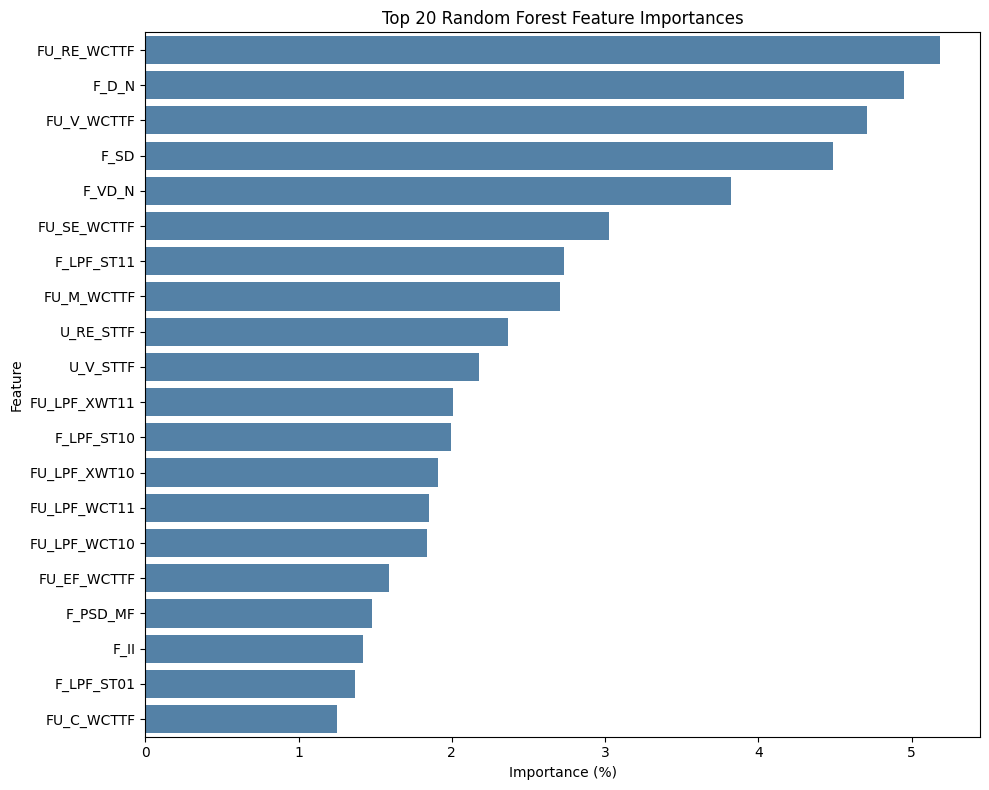

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

top_20_features = feature_importance_df.head(20)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=top_20_features,
    x="importance_percentage",
    y="feature",
    color="steelblue"
)

plt.title("Top 20 Random Forest Feature Importances")
plt.xlabel("Importance (%)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [16]:
config.FEATURE_IMPORTANCE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

feature_importance_path = (
    config.FEATURE_IMPORTANCE_DIR
    / "random_forest_baseline_feature_importance.csv"
)

feature_importance_df.to_csv(
    feature_importance_path,
    index=False
)

print(
    "Saved feature importance:",
    feature_importance_path
)

Saved feature importance: C:\Users\ASUS\Desktop\ML\Machine-Learning-Based-Fetal-Well-being-Classification-Using-Cardiotocography-Features\results\feature_importance\random_forest_baseline_feature_importance.csv


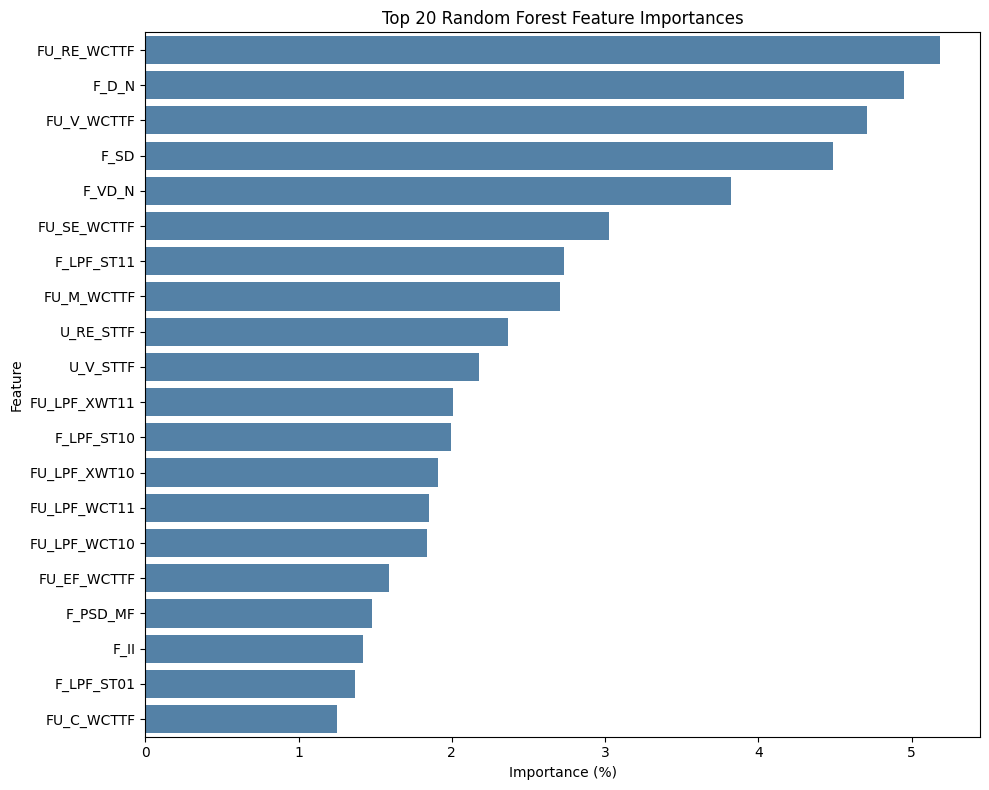

Saved feature-importance figure: C:\Users\ASUS\Desktop\ML\Machine-Learning-Based-Fetal-Well-being-Classification-Using-Cardiotocography-Features\results\figures\random_forest_top_20_feature_importance.png


In [17]:
config.FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

figure_path = (
    config.FIGURES_DIR
    / "random_forest_top_20_feature_importance.png"
)

top_20_features = feature_importance_df.head(20)

fig, ax = plt.subplots(figsize=(10, 8))

sns.barplot(
    data=top_20_features,
    x="importance_percentage",
    y="feature",
    color="steelblue",
    ax=ax
)

ax.set_title("Top 20 Random Forest Feature Importances")
ax.set_xlabel("Importance (%)")
ax.set_ylabel("Feature")

fig.tight_layout()
fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved feature-importance figure:", figure_path)